### E-Commerce Shopping Behavior Survey Analysis

**Objective:** This project Analyzes the survey data from 500 consumers to uncover insights into shopping preferences, payment methods, and demographic trends in e-commerce versus in-store environments. 

**Dataset:** "consumer_shopping_behavior_survey.csv"

The goal of this Analysis is to uncover how different consumer groups shop and pay, providing actionable insights to improve marketing campaigns and the online shopping experience.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [4]:
df = pd.read_csv("consumer_shopping_behavior_survey.csv")
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [5]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='str')

In [6]:
df.shape

(500, 30)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    str    
 2   Age                                 478 non-null    str    
 3   Gender                              484 non-null    str    
 4   Occupation_Status                   479 non-null    str    
 5   Country_Region                      480 non-null    str    
 6   Monthly_Income_Range                479 non-null    str    
 7   Shop_Most_Where                     484 non-null    str    
 8   Online_Shopping_Frequency           481 non-null    str    
 9   Preferred_Platform                  486 non-null    str    
 10  Primary_Device                      492 non-null    str    
 11  Top_Spending_Category               476 non-null    str 

In [8]:
df.isna().sum()

Response_ID                            0
Timestamp                              0
Age                                   22
Gender                                16
Occupation_Status                     21
Country_Region                        20
Monthly_Income_Range                  21
Shop_Most_Where                       16
Online_Shopping_Frequency             19
Preferred_Platform                    14
Primary_Device                         8
Top_Spending_Category                 24
Review_Influence_Score                15
Social_Ads_Influence_Score            21
Price_Comparison_Frequency            26
Discount_Importance_Score             23
Follows_Brands_On_Social              11
Likely_To_Buy_After_Ad_Score          25
Makes_Shopping_List                   24
Impulse_Purchase_Frequency            16
Return_Frequency                      17
Avg_Monthly_Spend_NonEssentials       20
Preferred_Payment_Method              15
Uses_BNPL_Installments                12
Online_Shopping_

In [9]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["Age"] = pd.to_numeric(df["Age"] ,errors ="coerce")
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%d/%m/%Y %H:%M:%S", errors="coerce")

In [13]:
df[["Age", "Timestamp"]].dtypes

Age                 float64
Timestamp    datetime64[us]
dtype: object

In [14]:
df["Age"].describe()

count    470.000000
mean      25.019149
std        7.515276
min       16.000000
25%       20.000000
50%       22.000000
75%       30.000000
max       50.000000
Name: Age, dtype: float64

In [15]:
df["Reason_Prefer_Online"].value_counts()

Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
Not applicable     38
Name: count, dtype: int64

### Feature Engineering: 

**Age Binning**

Continuous age data can be difficult to interpret in aggregate. By grouping respondents into generational buckets (Under 18, 18-25, 26-35, 36-50, 50+), we can more easily spot demographic trends in shopping behavior.

In [19]:
bins = [0, 18, 25, 35, 50, 100]
label = ["Under 18", "18-25", "26-35", "36-50", "50+"]

df["Age_Group"] = pd.cut(df["Age"], bins=bins, labels=label)




In [21]:
df["Age_Group"].value_counts()

Age_Group
18-25       228
26-35       110
Under 18     78
36-50        54
50+           0
Name: count, dtype: int64

In [22]:
columns_to_fill = ["Gender", "Occupation_Status", "Country_Region", "Shop_Most_Where", "Preferred_Platform", "Preferred_Payment_Method"]

In [26]:
for col in columns_to_fill:
    df[col] = df[col].fillna("Unknown")

Gender                      0
Occupation_Status           0
Country_Region              0
Shop_Most_Where             0
Preferred_Platform          0
Preferred_Payment_Method    0
dtype: int64

In [25]:
df[columns_to_fill].isna().sum()

Gender                      0
Occupation_Status           0
Country_Region              0
Shop_Most_Where             0
Preferred_Platform          0
Preferred_Payment_Method    0
dtype: int64

In [28]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group'],
      dtype='str')

In [29]:
last_6 = ['Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']

In [31]:
dropoff = df[last_6].isna().all(axis=1)

In [32]:
dropoff.sum()

np.int64(30)

In [33]:
df.loc[dropoff, "Timestamp"].dt.date.value_counts().sort_index()

Timestamp
2026-06-20    1
2026-06-22    1
2026-06-24    1
2026-06-29    1
2026-06-30    1
2026-07-02    1
2026-07-03    1
2026-07-05    1
2026-07-06    1
2026-07-07    2
2026-07-09    1
2026-07-10    1
2026-07-16    1
2026-07-24    2
2026-07-27    2
2026-07-28    1
2026-07-30    1
2026-08-02    1
2026-08-03    1
2026-08-15    2
2026-08-16    1
2026-08-17    1
2026-08-18    1
2026-08-19    1
2026-08-21    1
2026-08-24    1
Name: count, dtype: int64

In [34]:
pd.crosstab(df["Shop_Most_Where"], df["Reason_Prefer_InStore"], dropna = False)

Reason_Prefer_InStore,No delivery wait,Not applicable,Trust,Try product before buying,NaN
Shop_Most_Where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
Unknown,7,0,3,4,2


In [41]:
age_summary = df.groupby("Age_Group", observed= True).agg(
    avg_satisfaction = ("Online_Shopping_Satisfaction_Score", "mean"),
    avg_trust = ("Trust_In_Online_Reviews_Score", "mean"),
    avg_regret = ("Regret_After_Purchase_Frequency", "mean"),
    respondents = ("Response_ID", "count")
).round(2)

In [42]:
age_summary

,avg_satisfaction,avg_trust,avg_regret,respondents
Age_Group,,,,
Under 18,7.25,6.06,2.06,78
18-25,7.04,6.11,2.29,228
26-35,7.17,6.14,2.17,110
36-50,7.02,6.48,1.93,54


In [47]:
top_countries = df["Country_Region"].value_counts().head(8).index

In [48]:
top_countries

Index(['India', 'United States', 'Brazil', 'Mexico', 'Indonesia', 'Kenya',
       'Egypt', 'Philippines'],
      dtype='str', name='Country_Region')

In [53]:
country_summary = (
    df[df["Country_Region"].isin(top_countries)]
    .groupby("Country_Region")
    .agg(
        avg_satisfaction=("Online_Shopping_Satisfaction_Score", "mean"),
        bnpl_regular_rate=(
            "Uses_BNPL_Installments",
            lambda x: (x == "Yes, regularly").mean()
        ),
        respondents=("Response_ID", "count")
    )
)

country_summary

,avg_satisfaction,bnpl_regular_rate,respondents
Country_Region,,,
Brazil,7.114286,0.184211,38
Egypt,6.521739,0.040000,25
India,6.779661,0.181818,66
Indonesia,7.434783,0.153846,26
Kenya,7.240000,0.269231,26
Mexico,7.250000,0.085714,35
Philippines,7.090909,0.086957,23
United States,7.387755,0.053571,56


In [55]:
country_summary.describe()

,avg_satisfaction,bnpl_regular_rate,respondents
count,8.000000,8.000000,8.000000
mean,7.102392,0.131918,36.875000
std,0.310351,0.078653,15.986043
min,6.521739,0.040000,23.000000
25%,7.013097,0.077679,25.750000
50%,7.177143,0.120401,30.500000
75%,7.284439,0.182416,42.500000
max,7.434783,0.269231,66.000000


In [65]:
occupation_summary = df.groupby("Occupation_Status").agg(
    avg_impulse=("Impulse_Purchase_Frequency", "mean"),
    avg_discount_importance=("Discount_Importance_Score", "mean"),
    bnpl_regular_rate=(
        "Uses_BNPL_Installments", 
        lambda x:(x == "Yes, regularly").mean()
    ),
    respondent=("Response_ID", "count")
).round(2).sort_values("avg_impulse", ascending=False)

occupation_summary


,avg_impulse,avg_discount_importance,bnpl_regular_rate,respondent
Occupation_Status,,,,
Employed part-time,2.86,3.94,0.10,71
Student,2.61,3.80,0.13,238
Unknown,2.50,3.67,0.05,21
Employed full-time,2.46,3.90,0.14,118
Self-employed,2.45,3.78,0.12,33
Unemployed,2.44,3.47,0.05,19


In [66]:
pivot_payment =pd.pivot_table(
    df, index = "Shop_Most_Where", columns = "Preferred_Payment_Method",
    values = "Response_ID" , aggfunc = "count", fill_value=0
)

In [67]:
pivot_payment_pct = pivot_payment.div(pivot_payment.sum(axis=1), axis=0).round(2)

In [68]:
pivot_payment_pct

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,0.14,0.21,0.27,0.35,0.02
In-store only,0.14,0.25,0.23,0.34,0.04
Online only,0.11,0.22,0.24,0.39,0.03
Unknown,0.12,0.12,0.31,0.38,0.06


In [72]:
pivot_gender_spend = pd.pivot_table(
    df, index="Gender", columns = "Top_Spending_Category",
    values = "Response_ID", aggfunc = "count", fill_value=0  
)

In [73]:
pivot_gender_spend_pct = pivot_gender_spend.div(pivot_gender_spend.sum(axis=1), axis=0).round(2)

In [74]:
pivot_gender_spend_pct

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,0.06,0.09,0.38,0.14,0.21,0.12
Male,0.08,0.07,0.40,0.16,0.18,0.10
Prefer not to say,0.10,0.10,0.22,0.24,0.18,0.14
Unknown,0.00,0.13,0.40,0.13,0.20,0.13


## 2. Exploratory Data Analysis (EDA)

**Question:** What is the demographic breakdown of our survey respondents?

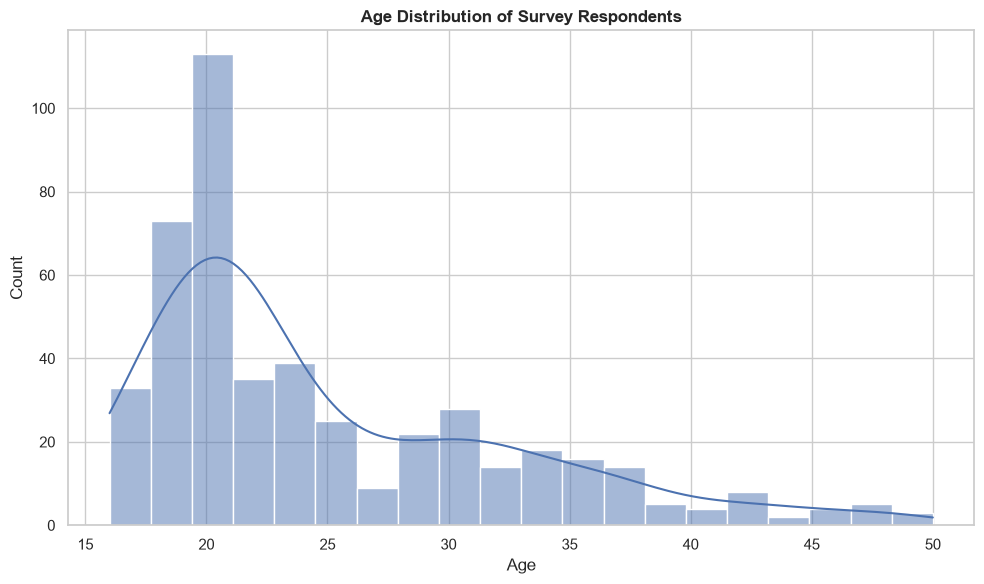

In [77]:
sns.histplot(df["Age"].dropna(), bins = 20, kde=True, color= "#4C72B0")
plt.title("Age Distribution of Survey Respondents", fontweight= "bold")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Takeaway:** The dataset skews heavily toward younger demographics, with the vast majority of respondents falling between the ages of 18 and 25.

**Question:** Does overall online shopping satisfaction vary significantly across different age groups?

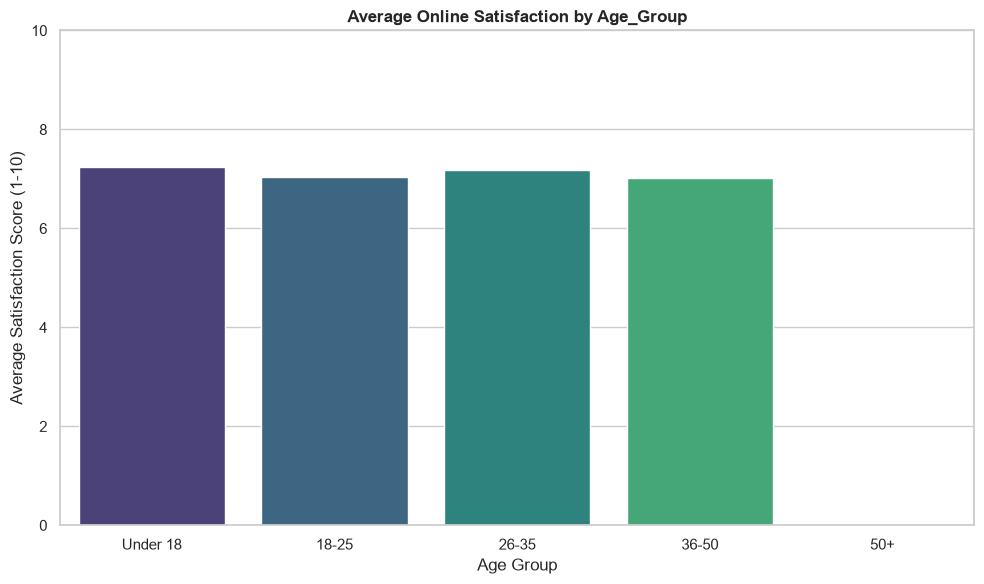

In [82]:
sns.barplot(x = age_summary.index, y=age_summary["avg_satisfaction"], palette="viridis")
plt.title("Average Online Satisfaction by Age_Group", fontweight="bold")
plt.xlabel("Age Group")
plt.ylabel("Average Satisfaction Score (1-10)")
plt.ylim(0,10)
plt.tight_layout()
plt.show()

**Takeaway:** Satisfaction remains relatively stable and high around 6 to 8
 across all age groups, though the "Under 18" cohort reports the highest average satisfaction.

**Question:** How does the preferred payment method change depending on where the consumer shops the most?

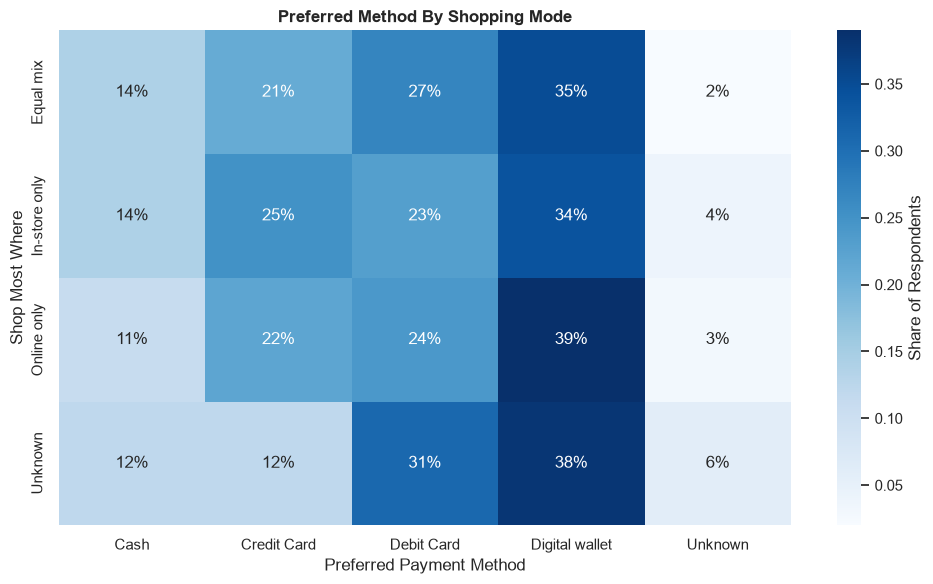

In [86]:
sns.heatmap(
    pivot_payment_pct,
    annot=True,
    cmap="Blues",
    fmt=".0%",
    cbar_kws={"label": "Share of Respondents"}
)
plt.title("Preferred Method By Shopping Mode" , fontweight="bold")
plt.xlabel("Preferred Payment Method")
plt.ylabel("Shop Most Where")
plt.tight_layout()
plt.show()


**Takeaway:** Digital wallets are the dominant payment method across all shopping modes, particularly for online-only shoppers (39%). Debit cards follow as the second most popular option, while cash remains relevant primarily for equal-mix and in-store shoppers.

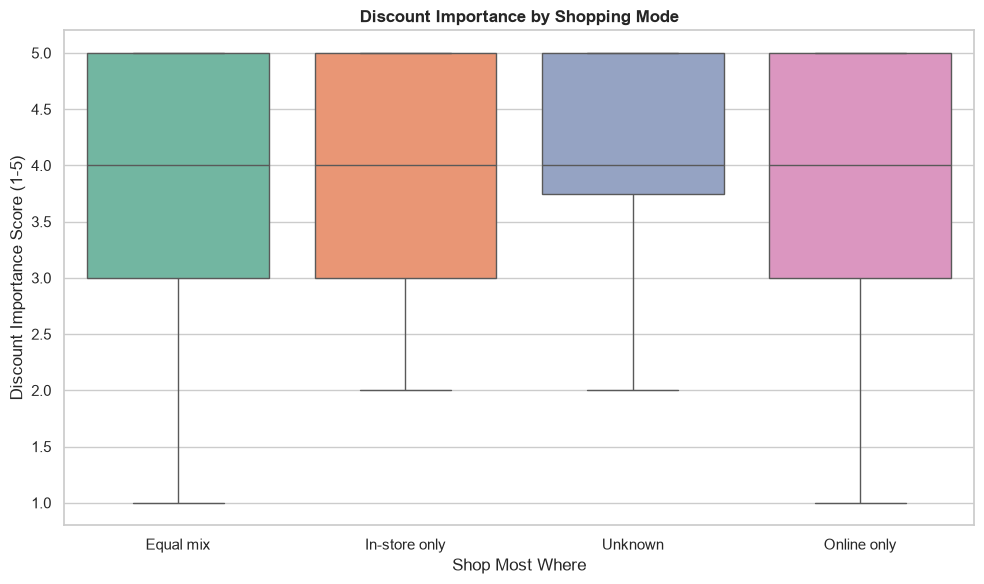

In [87]:
sns.boxplot(x = "Shop_Most_Where", y= "Discount_Importance_Score", data = df, palette="Set2")
plt.title("Discount Importance by Shopping Mode" , fontweight="bold")
plt.xlabel("Shop Most Where")
plt.ylabel("Discount Importance Score (1-5)")
plt.tight_layout()
plt.show()


###  **Final Conclusion**
**Digital Wallets Dominate:** Whether people shop online or in physical stores, they prefer using digital wallets. Businesses need to make sure they accept Apple Pay, Google Pay, and other easy mobile payment options.

**Younger Audience Engagement:** Most shoppers in this data are between 18 and 25 years old. Brands should design their websites, apps, and ads to appeal directly to Gen Z and younger millennials.

**High Baseline Satisfaction:** People are generally very satisfied with buying online, regardless of their age. To stand out, online stores need to offer easy returns or virtual "try-on" features to give shoppers the trust and hands-on experience they usually only get in a physical store.